In this notebook I want to prove that the basic functions in the class of value, neuron, layer, and MLP work as expected. 

In [1]:
from l1_notes.value import Value
from l1_notes.neuron_layer_MLP import Neuron, Layer, MLP

I also want to visualize the operations with a graph, so I am going to import some function from a library called graphviz

In [2]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    # create a digraph object
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        # for every value in the graph, create a rectangular node for it
        node_id = str(id(n))
        dot.node(name=node_id, label="{%s | data %.4f | %.4f}"%(n.label, n.data, n.grad), shape = "record")
        if n._op:
            # if this value is a result of an operation, create an operation node for it
            dot.node(name=node_id + n._op, label = n._op)
            # connect operation node to the value
            dot.edge(node_id + n._op, node_id)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

### Example for some simple operations

In [3]:
a = Value(1.0)
b = Value(2.0)
print(a+b)
print(a*b)
print(a-b)
print(a/b)
print(a**2)
print(a.tanh())
print(2*a)
print(3+a)

Value(data=3.0, grad=0)
Value(data=2.0, grad=0)
Value(data=-1.0, grad=0)
Value(data=0.5, grad=0)
Value(data=1.0, grad=0)
Value(data=0.7615941559557649, grad=0)
Value(data=2.0, grad=0)
Value(data=4.0, grad=0)


### A composition of simple function with visualization

In [4]:
a = Value(1.0)  ; a.label = "a"
b = Value(2.0)  ; b.label = "b"
c = Value(3.0)  ; c.label = "c"
d = Value(4.0)  ; d.label = "d"
e = Value(-1.0) ; e.label = "e"
x = (((a+b)*(e-d))-c+18.5).tanh() ; x.label = "x"
print(x)

Value(data=0.46211715726000974, grad=0)


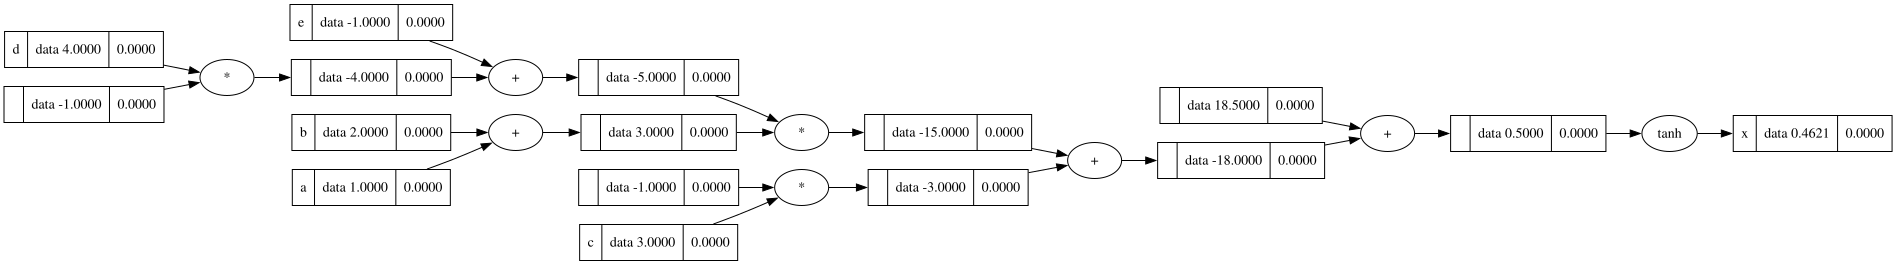

In [5]:
# draw_dot before backward propogation
draw_dot(x)

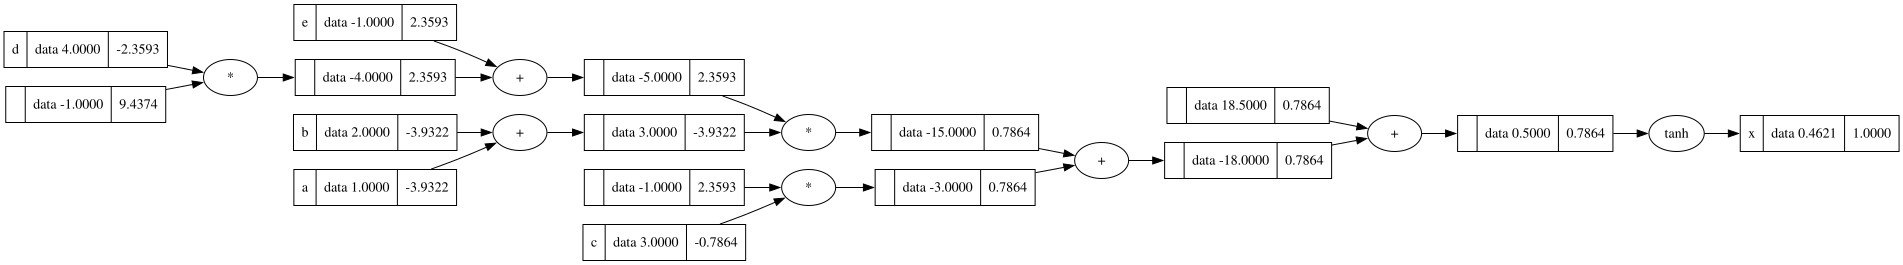

In [6]:
# draw_dot after backpropogation
x.backward()
draw_dot(x)

### Examples of higher level classes

In [7]:
# neuron
x = [1.0, 2.0, 3.0]
neuron = Neuron(3)
print(neuron)
print(neuron(x))

# layer
layer = Layer(3, 4)
print(layer)
print(layer(x))

# MLP
mlp = MLP(3, [4, 4, 1])
print(mlp)
output = mlp(x)
print(output)

tanh for a Neuron with 3 weight(s)
Value(data=0.9741178995632086, grad=0)
Layer of [tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s)]
[Value(data=-0.9657685649856455, grad=0), Value(data=0.9916405781012304, grad=0), Value(data=-0.6276559372913496, grad=0), Value(data=0.23385996444442703, grad=0)]
MLP of [Layer of [tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s), tanh for a Neuron with 3 weight(s)], Layer of [tanh for a Neuron with 4 weight(s), tanh for a Neuron with 4 weight(s), tanh for a Neuron with 4 weight(s), tanh for a Neuron with 4 weight(s)], Layer of [Linear for a Neuron with 4 weight(s)]]
Value(data=0.20856915654380231, grad=0)


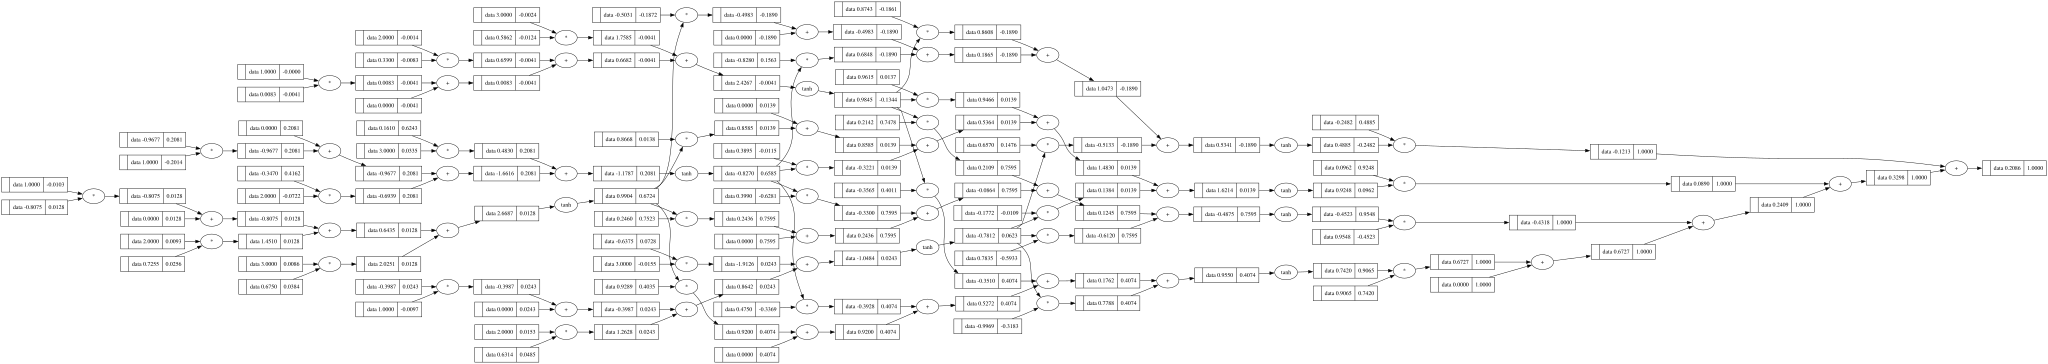

In [8]:
# a glimpse of the graph for the final MLP
output.backward()
draw_dot(output)

### Gradient descent to minimize loss

In [11]:
# inputs and expected outputs
xs = [
    [2.0, 3.0, -1.0, 5.0],
    [3.0, -1.0, 0.5, 1.5],
    [0.5, 1.0, 1.0, 3.2],
    [1.0, 1.0, -1.0, -3.4],
]
ys = [1.0, -1.0, -1.0, 1.0]

# Create the neural network 
n = MLP(4, [4,4,1])

In [14]:
for k in range(100):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update 
    for p in n.parameters():
        p.data -= 0.01 * p.grad

    print(f"At round {k}, the loss is {loss.data}")

At round 0, the loss is 0.0027737858273461156
At round 1, the loss is 0.002736344979264393
At round 2, the loss is 0.002699909568824478
At round 3, the loss is 0.0026644401504887353
At round 4, the loss is 0.002629899089010339
At round 5, the loss is 0.002596250471190109
At round 6, the loss is 0.0025634600220382393
At round 7, the loss is 0.002531495025118587
At round 8, the loss is 0.002500324246864246
At round 9, the loss is 0.002469917864663936
At round 10, the loss is 0.002440247398529073
At round 11, the loss is 0.0024112856461610825
At round 12, the loss is 0.0023830066212472403
At round 13, the loss is 0.0023553854948233253
At round 14, the loss is 0.0023283985395478376
At round 15, the loss is 0.0023020230767419945
At round 16, the loss is 0.002276237426056068
At round 17, the loss is 0.0022510208576304335
At round 18, the loss is 0.0022263535466257095
At round 19, the loss is 0.0022022165300034295
At round 20, the loss is 0.0021785916654438768
At round 21, the loss is 0.00215

In [15]:
# inspecting the parameters aat the moment
n.parameters()

[Value(data=0.6908746092096834, grad=4.4358537359901745e-05),
 Value(data=0.6394730718715013, grad=-8.655461337679548e-05),
 Value(data=-0.7979714298605621, grad=8.00305758314912e-05),
 Value(data=0.9346607753629549, grad=0.00026441479066025307),
 Value(data=0.009502728201374844, grad=-1.9828186742148086e-05),
 Value(data=-0.637004263503087, grad=8.460704727223906e-05),
 Value(data=0.7689071330126542, grad=0.0002151344414593443),
 Value(data=0.10252482281960747, grad=0.0002487678011541519),
 Value(data=-0.8716975824707255, grad=0.0007115780082861498),
 Value(data=-0.016255904303888107, grad=0.00022567419588039416),
 Value(data=-0.6214231855869039, grad=0.0005846743015251047),
 Value(data=0.9004277618896019, grad=0.002385272853048289),
 Value(data=-0.5830322074965613, grad=0.006696650768539763),
 Value(data=-0.14802590951332897, grad=0.012370462138680951),
 Value(data=-0.17219428786245664, grad=0.0045510635930185355),
 Value(data=0.2630154432494731, grad=-0.008264616672123594),
 Value(d